# Fake News Detection - Data Loading and EDA

In [1]:
import os
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
from sklearn.model_selection import train_test_split

# Folders for the dataset and saved figures
DATA_DIR = "../data/"
FIG_DIR = "../reports/figures/"

# For Google Colab: uncomment these lines to use Google Drive instead
# from google.colab import drive
# drive.mount("/content/drive")
# DATA_DIR = "/content/drive/MyDrive/fake-news/data/"
# FIG_DIR = "/content/drive/MyDrive/fake-news/reports/figures/"

# Create the figures folder if it does not exist
os.makedirs(FIG_DIR, exist_ok=True)

In [2]:
# Load the WELFake dataset
df = pd.read_csv(DATA_DIR + "WELFake_Dataset.csv", index_col=0)

print("Shape:", df.shape)
print("Columns:", list(df.columns))
df.head()

Shape: (72134, 3)
Columns: ['title', 'text', 'label']


,title,text,label
0,LAW ENFORCEMENT ON HIGH ALERT Following Threat...,No comment is expected from Barack Obama Membe...,1
1,NaN,Did they post their votes for Hillary already?,1
2,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...,"Now, most of the demonstrators gathered last ...",1
3,"Bobby Jindal, raised Hindu, uses story of Chri...",A dozen politically active pastors came here f...,0
4,SATAN 2: Russia unvelis an image of its terrif...,"The RS-28 Sarmat missile, dubbed Satan 2, will...",1


In [3]:
# Print 5 random titles for each label so we can check which label means fake
for label in [0, 1]:
    print(f"--- Label {label} ---")
    titles = df[df["label"] == label]["title"].dropna()
    for title in titles.sample(5, random_state=1):
        print("-", title)
    print()

--- Label 0 ---
- Candles May Have Caused Fire That Gutted Serbian Church, Officials Say - The New York Times
- Single Mother Seeks to Give Daughter the Peace That Eluded Her - The New York Times
- Cliff Sims: House Healthcare Bill ’Still a Work in Progress’
- Only a Rumbling Volcano Could Make North Korea and the West Play Nice - The New York Times
- New Ontario Law Enables Gov’t to Seize Children from Parents Opposing Gender Transition

--- Label 1 ---
- “Sex Shop Kierkegaard: punto de encuentro para amantes del placer intelectual”
- FATHER OF STUDENT Released From N. Korean Prison Slams Obama…Uses ONE WORD To Describe President Trump That Will Make Liberals Cringe [VIDEO]
- The Path To Total Dictatorship: America’s “Shadow Government” And Its Silent Coup
- John Derbyshire On Peter Thiel On Trump
- TEXAS PIG FARMER Has BRILLIANT Idea After Muslims DEMAND He Moves So They Can Build A Mosque [VIDEO]



In [4]:
# Label value that means fake news.
# Verified by checking sample titles: label 1 is fake, label 0 is real.
FAKE_LABEL = 1

# New column: 1 = fake, 0 = real
df["is_fake"] = (df["label"] == FAKE_LABEL).astype(int)
df["is_fake"].value_counts()

is_fake
1    37106
0    35028
Name: count, dtype: int64

## Label verification

- Label 0 titles look like normal news (many end with "- The New York Times"); label 1 titles are sensational (ALL CAPS, "[VIDEO]", "BRILLIANT", "DEMAND").
- Counts match the WELFake paper (37,106 fake, 35,028 real), so label 1 = fake.
- Note for cleaning: publisher suffixes like "- The New York Times" are a source artifact (data leakage) and must be removed in the cleaning step.

## Exploratory Data Analysis

In [5]:
# Column types and non-null counts
df.info()

# Missing values per column
print("\nMissing values per column:")
print(df.isnull().sum())

# Rows that repeat the same article text (missing texts are excluded)
print("\nDuplicate rows by text:", df["text"].dropna().duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 72134 entries, 0 to 72133
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   title    71576 non-null  str  
 1   text     72095 non-null  str  
 2   label    72134 non-null  int64
 3   is_fake  72134 non-null  int64
dtypes: int64(2), str(2)
memory usage: 235.0 MB

Missing values per column:
title      558
text        39
label        0
is_fake      0
dtype: int64



Duplicate rows by text: 9377


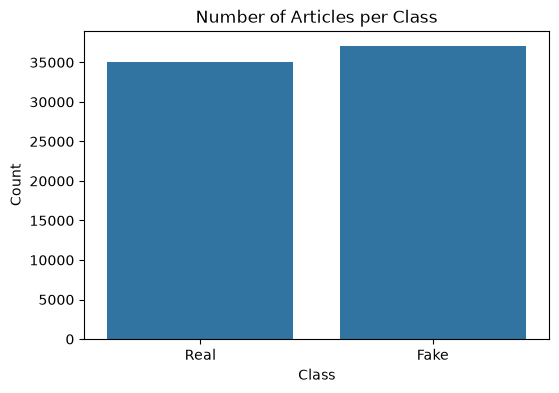

In [6]:
# Readable class names for plots
df["class_name"] = df["is_fake"].map({0: "Real", 1: "Fake"})

# Number of articles in each class
plt.figure(figsize=(6, 4))
sns.countplot(x="class_name", data=df, order=["Real", "Fake"])
plt.title("Number of Articles per Class")
plt.xlabel("Class")
plt.ylabel("Count")
plt.savefig(FIG_DIR + "class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

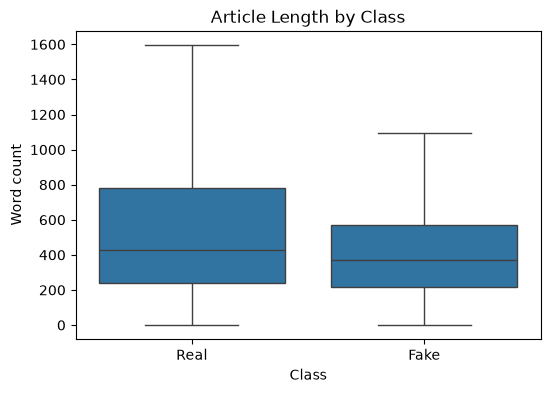

,count,mean,std,min,25%,50%,75%,max
class_name,,,,,,,,
Fake,37106.0,505.562012,677.121991,0.0,217.0,369.0,568.0,24234.0
Real,35028.0,577.615536,563.115638,0.0,241.0,427.0,783.0,14641.0


In [7]:
# Number of words in each article (missing text counts as 0 words)
df["word_count"] = df["text"].fillna("").str.split().str.len()

# Article length by class, hiding outliers
plt.figure(figsize=(6, 4))
sns.boxplot(x="class_name", y="word_count", data=df, order=["Real", "Fake"], showfliers=False)
plt.title("Article Length by Class")
plt.xlabel("Class")
plt.ylabel("Word count")
plt.savefig(FIG_DIR + "length_by_class.png", dpi=150, bbox_inches="tight")
plt.show()

# Word count summary for each class
df.groupby("class_name")["word_count"].describe()

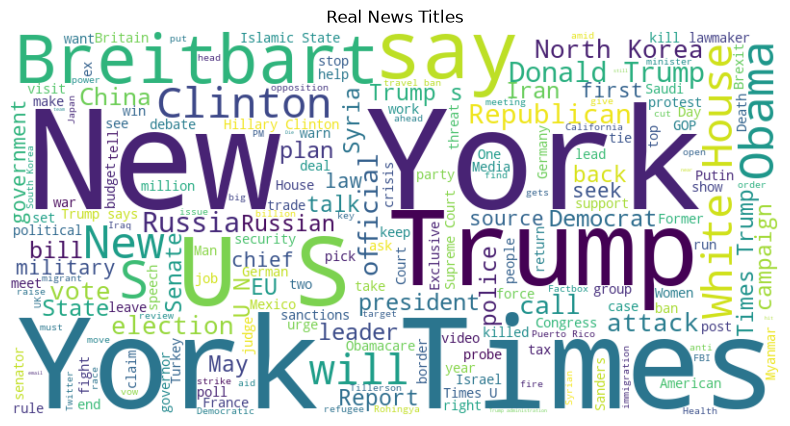

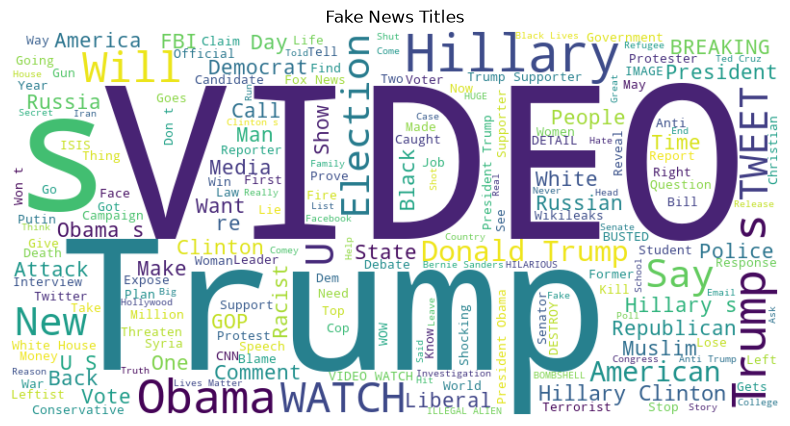

In [8]:
# Word cloud of 5000 random titles for each class
for name in ["Real", "Fake"]:
    titles = df[df["class_name"] == name]["title"].dropna().sample(5000, random_state=1)
    wc = WordCloud(width=800, height=400, background_color="white", random_state=1).generate(" ".join(titles))

    plt.figure(figsize=(10, 5))
    plt.imshow(wc, interpolation="bilinear")
    plt.axis("off")
    plt.title(f"{name} News Titles")
    plt.savefig(FIG_DIR + f"wordcloud_{name.lower()}.png", dpi=150, bbox_inches="tight")
    plt.show()

## Observations

- 9,377 rows repeat another row's text (missing texts excluded).
- After cleaning and removing duplicates, the class balance changed (real is now the majority) because many fake articles were duplicates; stratified splitting keeps this ratio the same in train and test.
- 
- 

## Data Cleaning and Split

In [9]:
print("Shape before cleaning:", df.shape)

# Replace missing title/text with empty text
df["title"] = df["title"].fillna("")
df["text"] = df["text"].fillna("")

# Join title and text into one column
df["content"] = (df["title"] + " " + df["text"]).str.strip()

# Drop very short articles and repeated content
df = df[df["content"].str.len() >= 50]
df = df.drop_duplicates(subset="content").reset_index(drop=True)

print("Shape after cleaning:", df.shape)

Shape before cleaning: (72134, 6)


Shape after cleaning: (63547, 7)


In [10]:
# Most common title endings after the last " - " (often the publisher name)
for name in ["Real", "Fake"]:
    titles = df[(df["class_name"] == name) & df["title"].str.contains(" - ", regex=False)]["title"]
    endings = titles.str.rsplit(" - ", n=1).str[-1].str.strip()
    print(f"--- {name} ---")
    print(endings.value_counts().head(15))
    print()

--- Real ---
title
The New York Times    6223
Breitbart             2338
sources                 38
source                   7
poll                     7
Reuters/Ipsos poll       6
RIA                      6
agencies                 5
The Boston Globe         4
Ifax                     4
Politics.com             4
NYTimes.com              3
statement                3
document                 3
official                 3
Name: count, dtype: int64

--- Fake ---
title
America's Finest News Source    85
Russia News Now                 53
RT Arabic                       15
RT                              11
Conservative                     9
USAPoliticsNow                   8
Wikileaks                        7
Morning News USA                 6
New Earth Media                  5
Tyler Durden                     4
Jason Ditz                       3
USA News Insider                 3
ICH                              3
Fort Russ                        3
Upside Down Media                3
Name:

In [11]:
# Patterns that show where an article came from, not what it says
ARTIFACT_PATTERNS = [
    r"\s-\s(the new york times|breitbart)\b",                  # publisher suffixes seen 100+ times above
    # Source names anywhere in the text. No word boundaries, because some names
    # are glued to the next word in this dataset (for example "ReutersNorth").
    # \s+ also matches unusual spaces between words.
    r"reuters|new\s+york\s+times|nytimes|breitbart\s+news|breitbart|21st\s+century\s+wire|21wire",
    r"(featured )?(image via|photo by|image credit)[^.]{0,80}",  # image credits
    r"getty images",
    r"@\w+",                                                    # twitter handles
]


def remove_artifacts(text):
    """Remove source names and image credits from an article."""
    # Dateline like "WASHINGTON (Reuters) - ".
    # Case-sensitive so it only takes the city name in capitals, not the end of the title.
    text = re.sub(r"(\b[A-Z][A-Z .,/'-]*)?\(Reuters\)\s*-\s*", " ", text)

    # All other patterns ignore upper/lower case
    for pattern in ARTIFACT_PATTERNS:
        text = re.sub(pattern, " ", text, flags=re.IGNORECASE)

    # Remove extra spaces left behind
    return re.sub(r"\s+", " ", text).strip()


# This takes about 30 seconds
df["content"] = df["content"].apply(remove_artifacts)

# Drop articles that became identical after cleaning,
# so no article can end up in both train and test
rows_before = len(df)
df = df.drop_duplicates(subset="content").reset_index(drop=True)
print("Duplicate rows dropped after cleaning:", rows_before - len(df))

# Fake/real counts after cleaning
print(df["class_name"].value_counts())

Duplicate rows dropped after cleaning: 3
class_name
Real    34788
Fake    28756
Name: count, dtype: int64


In [12]:
# Leakage check: how many articles still mention these sources
SOURCE_NAMES = ["reuters", "new york times", "nytimes", "breitbart", "breitbart news", "21st century wire", "21wire"]

for word in SOURCE_NAMES:
    has_word = df["content"].str.contains(word, case=False, regex=False)
    real_count = (has_word & (df["is_fake"] == 0)).sum()
    fake_count = (has_word & (df["is_fake"] == 1)).sum()
    print(f"{word}: {has_word.sum()} rows (Real: {real_count}, Fake: {fake_count})")

reuters: 0 rows (Real: 0, Fake: 0)
new york times: 0 rows (Real: 0, Fake: 0)


nytimes: 0 rows (Real: 0, Fake: 0)


breitbart: 0 rows (Real: 0, Fake: 0)
breitbart news: 0 rows (Real: 0, Fake: 0)


21st century wire: 0 rows (Real: 0, Fake: 0)


21wire: 0 rows (Real: 0, Fake: 0)


In [13]:
# 80% train, 20% test, with the same fake/real ratio in both
train_df, test_df = train_test_split(
    df[["content", "is_fake"]],
    test_size=0.2,
    stratify=df["is_fake"],
    random_state=42,
)

# Save the splits for the modelling notebooks
train_df.to_csv(DATA_DIR + "train.csv", index=False)
test_df.to_csv(DATA_DIR + "test.csv", index=False)

print("Train rows:", len(train_df))
print("Test rows:", len(test_df))
print("\nTrain fake/real ratio:")
print(train_df["is_fake"].value_counts(normalize=True))
print("\nTest fake/real ratio:")
print(test_df["is_fake"].value_counts(normalize=True))

Train rows: 50835
Test rows: 12709

Train fake/real ratio:
is_fake
0    0.547457
1    0.452543
Name: proportion, dtype: float64

Test fake/real ratio:
is_fake
0    0.547486
1    0.452514
Name: proportion, dtype: float64


## Why this cleaning

- Removing publisher names and source tags prevents data leakage: the model must learn from the writing, not from where the article was published.
- `stratify` keeps the same fake/real ratio in the train and test sets.
- `random_state=42` makes the split the same every time the notebook runs.